# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** _preencha_ · **Tema:** _preencha_

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [3]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/jterr3s/IA-2026-02-TP-Chatcom.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [4]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

🔨 TODO: preencha o `grupo.yaml` da raiz do repositório (tema e intenções
**validados com o professor**) antes de rodar esta seção.

In [23]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])

Grupo: TODO: nome do grupo (ex.: Grupo 3) | Tema: Chatcom


,intenção,descrição
0,periodo_disciplina,em que período uma disciplina aparece na grade
1,disciplinas_periodo,quais disciplinas formam um período
2,obrigatorias,"disciplinas obrigatórias do curso, ou se uma disciplina é obrigatória"
3,optativas,disciplinas complementares oferecidas
4,dados_disciplina,código e carga horária de uma disciplina
5,prerequisitos,pré-requisitos de uma disciplina
6,disciplina_no_curso,"se um curso tem determinada disciplina, ou diferenças entre cursos"
7,cursos_facom,cursos de graduação oferecidos pela FACOM
8,docentes,corpo docente de um curso


---
## 2. Dados

🔨 TODO: descreva aqui (em markdown) **como** os dados foram construídos: quem
escreveu, que fontes foram coletadas, que LLM e que *prompts* foram usados, como os
negativos difíceis foram pensados, como o teste foi obtido (ex.: formulário
respondido por N colegas).

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [12]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: ['3 texto(s) duplicado(s) dentro do arquivo']
Problemas no teste:  nenhum
Vazamento treino→teste: ['Obrigado', 'Quem são os professores da facom?']


origem,humano,llm,total
intencao,,,
chitchat,20,80,100
cursos_facom,12,40,52
dados_disciplina,12,40,52
disciplina_no_curso,12,40,52
disciplinas_periodo,12,40,52
docentes,12,40,52
fora_dominio,32,120,152
obrigatorias,12,40,52
optativas,12,40,52


origem,coletado,total
intencao,,
chitchat,16,16
cursos_facom,6,6
dados_disciplina,8,8
disciplina_no_curso,8,8
disciplinas_periodo,8,8
docentes,8,8
fora_dominio,24,24
obrigatorias,8,8
optativas,8,8


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [ ]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

🔨 TODO: análise exploratória - tamanho das mensagens por classe, palavras mais
frequentes por intenção, exemplos de negativos difíceis, diferenças entre frases
humanas e de LLM...

In [13]:
import re
from collections import Counter

stopwords_pt = {
    "a", "o", "as", "os", "de", "do", "da", "dos", "das", "em", "no", "na",
    "nos", "nas", "para", "pra", "por", "com", "sem", "que", "q", "é", "eh",
    "e", "ou", "um", "uma", "se", "ao", "à", "qual", "quais", "como", "tem", "ter"
}

# 1. Tamanho médio por origem (humano / coletado vs llm)
for nome, df in [("Treino", treino), ("Teste", teste)]:
    df_tmp = df.copy()
    df_tmp["chars"] = df_tmp["texto"].str.len()
    df_tmp["palavras"] = df_tmp["texto"].str.split().str.len()
    print(f"=== {nome.upper()} — TAMANHO POR ORIGEM (Total: {len(df_tmp)}) ===")
    display(df_tmp.groupby("origem").agg(
        qtd=("texto", "count"),
        media_chars=("chars", "mean"),
        media_palavras=("palavras", "mean")
    ).round(1))

# 2. Tamanho médio por intenção (Treino)
treino_tmp = treino.copy()
treino_tmp["chars"] = treino_tmp["texto"].str.len()
treino_tmp["palavras"] = treino_tmp["texto"].str.split().str.len()
print("\n=== TREINO — TAMANHO POR INTENÇÃO ===")
display(treino_tmp.groupby("intencao").agg(
    qtd=("texto", "count"),
    media_chars=("chars", "mean"),
    media_palavras=("palavras", "mean")
).round(1))

# 3. Top 5 palavras mais frequentes por intenção
top_palavras = {}
for intencao, grupo in treino.groupby("intencao"):
    tokens = []
    for txt in grupo["texto"].str.lower():
        palavras = re.findall(r"\b[a-záéíóúâêôãõç]{2,}\b", txt)
        tokens.extend([p for p in palavras if p not in stopwords_pt])
    top_palavras[intencao] = ", ".join([f"{p} ({c})" for p, c in Counter(tokens).most_common(5)])

print("\n=== TOP 5 PALAVRAS POR INTENÇÃO (TREINO) ===")
display(pd.Series(top_palavras, name="Palavras mais frequentes"))

=== TREINO — TAMANHO POR ORIGEM (Total: 722) ===


,qtd,media_chars,media_palavras
origem,,,
humano,162,48.1,8.2
llm,560,49.5,8.3


=== TESTE — TAMANHO POR ORIGEM (Total: 110) ===


,qtd,media_chars,media_palavras
origem,,,
coletado,110,47.9,8.2



=== TREINO — TAMANHO POR INTENÇÃO ===


,qtd,media_chars,media_palavras
intencao,,,
chitchat,100,22.1,4.1
cursos_facom,52,53.8,9.5
dados_disciplina,52,51.1,8.9
disciplina_no_curso,52,57.8,9.5
disciplinas_periodo,52,58.5,10.3
docentes,52,54.1,8.9
fora_dominio,152,42.5,7.6
obrigatorias,52,59.6,9.2
optativas,52,56.0,8.7



=== TOP 5 PALAVRAS POR INTENÇÃO (TREINO) ===


chitchat                                             você (24), tudo (13), oi (12), bom (10), dia (10)
cursos_facom                         curso (28), facom (22), computação (16), engenharia (15), me (11)
dados_disciplina                            ementa (15), me (14), carga (13), horária (11), horas (11)
disciplina_no_curso            curso (23), sistemas (14), engenharia (14), computação (14), grade (11)
disciplinas_periodo      semestre (26), período (24), disciplinas (20), matérias (19), engenharia (12)
docentes                                   quem (23), professores (16), aula (15), facom (14), me (10)
fora_dominio                                        faço (34), me (25), facom (12), ufms (9), onde (9)
obrigatorias           obrigatória (28), computação (13), obrigatórias (12), curso (9), engenharia (9)
optativas                  optativa (26), optativas (25), computação (10), matéria (9), engenharia (8)
periodo_disciplina               semestre (24), período (18), fica (10), 

---
## 3. Representações de texto

🔨 TODO: escolha **pelo menos duas** representações para comparar. Os construtores
de `chatbot/representacoes.py` aceitam os parâmetros do `TfidfVectorizer`
(`ngram_range`, `min_df`, `stop_words`, ...). Embeddings pré-treinados
(`EmbeddingsSentenca`) são opcionais.

In [14]:
REPRESENTACOES = {
    "TF-IDF palavras (padrão)": tfidf_palavras,
    "TF-IDF caracteres (padrão)": tfidf_caracteres,
    "TF-IDF palavras (unigramas)": lambda: tfidf_palavras(ngram_range=(1, 1)),#falta de acentuação
    "TF-IDF palavras (1-2 gramas, min_df=2)": lambda: tfidf_palavras(ngram_range=(1, 2), min_df=2),#expressao composta
    "TF-IDF caracteres (3-5 gramas)": lambda: tfidf_caracteres(ngram_range=(3, 5)),#remocao de termos raros
}

---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

🔨 TODO: compare **pelo menos três algoritmos vistos em aula**, com validação
cruzada estratificada **só no treino**. Classificadores que ainda serão
apresentados na disciplina (KNN, Naive Bayes, SVM...) podem entrar quando forem
vistos.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [16]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive Bayes (Multinomial)": lambda: MultinomialNB(),
    "SVM Linear": lambda: LinearSVC(C=1.0, random_state=RANDOM_STATE),
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres (3-5 gramas),SVM Linear,0.924,0.019,0.946,1.000
1,TF-IDF caracteres (padrão),Rede neural (MLP),0.924,0.024,0.946,1.000
2,TF-IDF caracteres (3-5 gramas),Regressão logística,0.922,0.020,0.943,1.000
3,TF-IDF caracteres (padrão),SVM Linear,0.917,0.032,0.942,1.000
4,TF-IDF caracteres (padrão),Regressão logística,0.916,0.035,0.940,1.000
5,TF-IDF palavras (padrão),Rede neural (MLP),0.914,0.032,0.939,1.000
6,TF-IDF palavras (unigramas),SVM Linear,0.914,0.023,0.940,1.000
7,TF-IDF palavras (unigramas),Rede neural (MLP),0.913,0.023,0.938,1.000
8,"TF-IDF palavras (1-2 gramas, min_df=2)",SVM Linear,0.913,0.027,0.938,0.988
9,TF-IDF caracteres (3-5 gramas),Rede neural (MLP),0.911,0.018,0.935,1.000


🔨 TODO: ajuste de hiperparâmetros dos melhores candidatos (`GridSearchCV`), curva
de validação e escolha justificada do modelo final de escopo.

Melhores parâmetros: {'classificador__C': 50, 'vetorizador__ngram_range': (3, 5)} | F1: 0.927


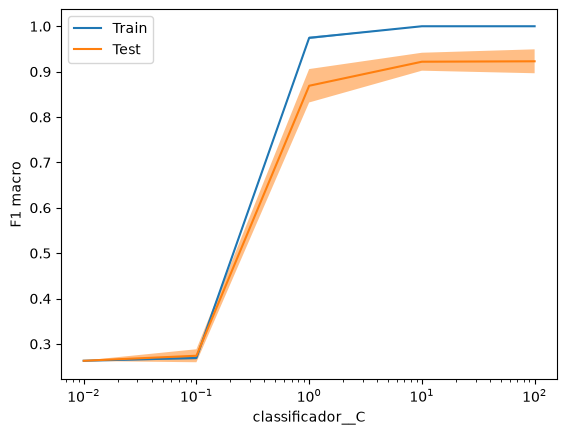

In [17]:
from sklearn.model_selection import ValidationCurveDisplay

# 1. Ajuste de hiperparâmetros (GridSearchCV)
busca_escopo = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"vetorizador__ngram_range": [(2, 4), (3, 5)], "classificador__C": [0.1, 1, 10, 50]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_escopo.fit(treino["texto"], treino["escopo"])
clf_escopo = busca_escopo.best_estimator_
print("Melhores parâmetros:", busca_escopo.best_params_, "| F1:", round(busca_escopo.best_score_, 3))

# 2. Curva de validação pronta do scikit-learn
ValidationCurveDisplay.from_estimator(
    clf_escopo, treino["texto"], treino["escopo"],
    param_name="classificador__C", param_range=[0.01, 0.1, 1, 10, 100],
    cv=cv, scoring="f1_macro", n_jobs=-1
)
plt.show()

📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

In [ ]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

---
## 5. Classificador de tema (intenções do domínio)

🔨 TODO: mesma metodologia, treinando **só** com as mensagens do domínio.

In [19]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres (3-5 gramas),SVM Linear,0.951,0.022,0.951,0.998
1,TF-IDF caracteres (padrão),SVM Linear,0.947,0.026,0.947,0.999
2,TF-IDF caracteres (3-5 gramas),Regressão logística,0.946,0.018,0.947,0.998
3,TF-IDF caracteres (padrão),Regressão logística,0.942,0.017,0.943,0.999
4,TF-IDF palavras (unigramas),SVM Linear,0.938,0.013,0.938,1.000
5,TF-IDF palavras (padrão),SVM Linear,0.927,0.018,0.928,1.000
6,TF-IDF palavras (unigramas),Regressão logística,0.919,0.024,0.919,1.000
7,"TF-IDF palavras (1-2 gramas, min_df=2)",SVM Linear,0.914,0.018,0.915,1.000
8,TF-IDF caracteres (padrão),Rede neural (MLP),0.913,0.027,0.913,1.000
9,TF-IDF palavras (padrão),Regressão logística,0.913,0.014,0.913,1.000


Melhores parâmetros: {'classificador__C': 10, 'vetorizador__ngram_range': (3, 5)} | F1: 0.946


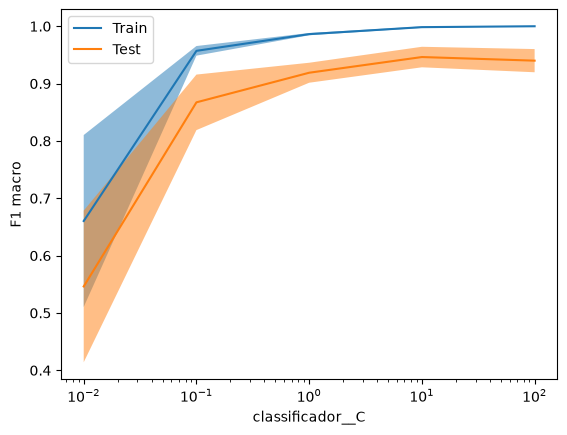

In [20]:
busca_tema = GridSearchCV(
    Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000))]),
    param_grid={"vetorizador__ngram_range": [(2, 4), (3, 5)], "classificador__C": [0.1, 1, 10, 50]},
    scoring="f1_macro", cv=cv, n_jobs=-1,
)
busca_tema.fit(treino_dom["texto"], treino_dom["intencao"])
clf_tema = busca_tema.best_estimator_
print("Melhores parâmetros:", busca_tema.best_params_, "| F1:", round(busca_tema.best_score_, 3))

ValidationCurveDisplay.from_estimator(
    clf_tema, treino_dom["texto"], treino_dom["intencao"],
    param_name="classificador__C", param_range=[0.01, 0.1, 1, 10, 100],
    cv=cv, scoring="f1_macro", n_jobs=-1
)
plt.show()

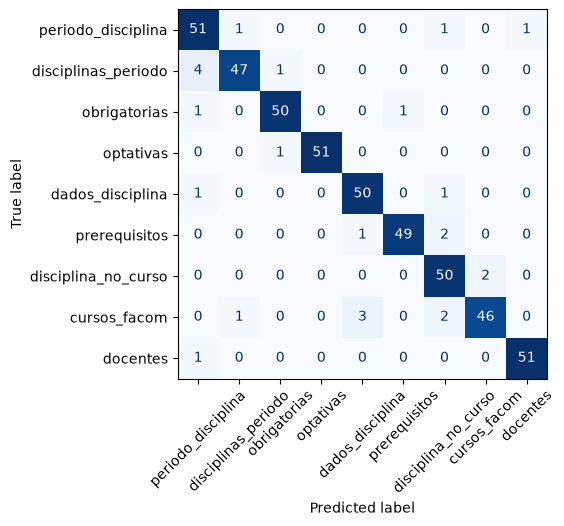

                     precision    recall  f1-score   support

       cursos_facom       0.96      0.88      0.92        52
   dados_disciplina       0.93      0.96      0.94        52
disciplina_no_curso       0.89      0.96      0.93        52
disciplinas_periodo       0.96      0.90      0.93        52
           docentes       0.98      0.98      0.98        52
       obrigatorias       0.96      0.96      0.96        52
          optativas       1.00      0.98      0.99        52
 periodo_disciplina       0.88      0.94      0.91        54
      prerequisitos       0.98      0.94      0.96        52

           accuracy                           0.95       470
          macro avg       0.95      0.95      0.95       470
       weighted avg       0.95      0.95      0.95       470



In [21]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

---
## 6. Limiar de confiança

🔨 TODO: escolha `roteamento.limiar_tema` (no `grupo.yaml`) com base nas
probabilidades da validação cruzada, como na seção 9 do exemplo. Justifique.

,limiar,cobertura,acuracia_aceitos
6,0.30,0.983,0.952
10,0.40,0.923,0.968
12,0.45,0.906,0.969
14,0.50,0.868,0.971
16,0.55,0.826,0.979
18,0.60,0.770,0.983
20,0.65,0.702,0.988
22,0.70,0.638,0.987
24,0.75,0.568,0.993
26,0.80,0.500,0.996


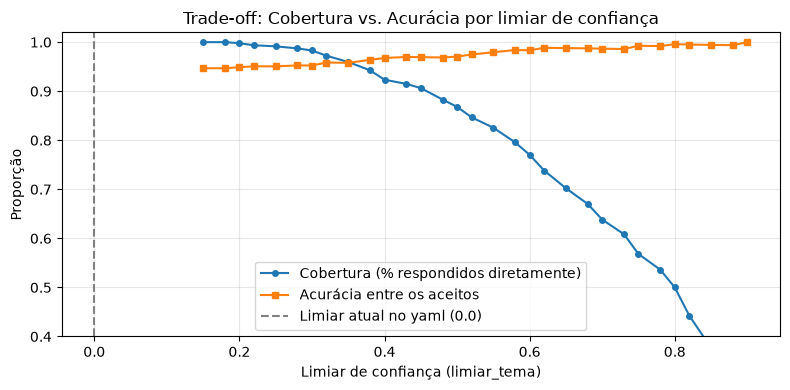

In [22]:
probs_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv, method="predict_proba")
conf_max = probs_tema.max(axis=1)
pred_tema = clf_tema.classes_[probs_tema.argmax(axis=1)]
acertou = (pred_tema == treino_dom["intencao"].to_numpy())

limiares = np.linspace(0.15, 0.90, 31)
linhas_limiar = []
for t in limiares:
    aceitos = conf_max >= t
    cobertura = aceitos.mean()
    acuracia = acertou[aceitos].mean() if aceitos.any() else np.nan
    linhas_limiar.append({"limiar": round(t, 2), "cobertura": cobertura, "acuracia_aceitos": acuracia})

df_limiar = pd.DataFrame(linhas_limiar)

# Exibe a tabela com alguns pontos-chave para facilitar a escolha
display(df_limiar[df_limiar["limiar"].isin([0.30, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80])].round(3))

# Plota a curva Cobertura x Acurácia nos aceitos
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df_limiar["limiar"], df_limiar["cobertura"], marker="o", markersize=4, label="Cobertura (% respondidos diretamente)")
ax.plot(df_limiar["limiar"], df_limiar["acuracia_aceitos"], marker="s", markersize=4, label="Acurácia entre os aceitos")
ax.axvline(config.limiar_tema, color="gray", linestyle="--", label=f"Limiar atual no yaml ({config.limiar_tema})")
ax.set_xlabel("Limiar de confiança (limiar_tema)")
ax.set_ylabel("Proporção")
ax.set_title("Trade-off: Cobertura vs. Acurácia por limiar de confiança")
ax.set_ylim(0.4, 1.02)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

---
## 7. Salvar os modelos finais

In [24]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

🔨 TODO: reúna os documentos em `documentos/` (uma subpasta por intenção + `geral/`,
com o `FONTES.md`), ajuste `persona` e `contato` no `grupo.yaml` e mostre conversas
que ilustrem acertos **e** limitações do bot (inclusive perguntas cuja resposta
não está nos documentos). Se o grupo alterou o grafo (`chatbot/grafo.py`),
explique aqui o que mudou.

Antes: configure a chave no `.env` (ou nos *Secrets* do Colab) e rode
`python scripts/testar_llm.py`.

In [28]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

# 🔨 TODO: teste a busca com perguntas do seu domínio (não gasta créditos)
pergunta, intencao = "Quais cursos tem na FACOM?", config.nomes_intencoes[0]
for tr, sim in base.buscar(pergunta, intencao=intencao):
    print(f"{sim:.2f}  {tr.fonte} | {tr.texto[:80]!r}")

trechos  \
intencao            fonte                                                                                       
cursos_facom        cursos_facom\cursos_graduacao_facom.txt.txt                                             2   
dados_disciplina    dados_disciplina\PPC-CC-completo.2026-02.pdf                                          532   
                    dados_disciplina\PPC-ES_2023_Completo.pdf                                             502   
                    dados_disciplina\Projeto-Pedagogico-SI-2026-Completo.pdf                              482   
                    dados_disciplina\RESOLUCAO-COGRAD-n-1309-de-08-12-2025.pdf                            355   
                    dados_disciplina\ppc-bacharelado-ia.pdf                                               501   
disciplina_no_curso disciplina_no_curso\» Quadro comparativo entre os cursos de graduaçãoFaculdad...        3   
disciplinas_periodo disciplinas_periodo\PPC-CC-completo.2026-02.pdf                                       532   
                    disciplinas_periodo\PPC-ES_2023_Completo.pdf                                          502   
                    disciplinas_periodo\Projeto-Pedagogico-SI-2026-Completo.pdf                           482   
                    disciplinas_periodo\RESOLUCAO-COGRAD-n-1309-de-08-12-2025.pdf                         355   
                    disciplinas_periodo\bcc.md                                                              3   
                    disciplinas_periodo\ppc-bacharelado-ia.pdf                                            501   
docentes            docentes\Ciência da Computação (1904) - UFMS - Professores.html                        14   
                    docentes\Engenharia de Computação (1905) - UFMS - Professores.html                     18   
                    docentes\Engenharia de Software (1906) - UFMS - Professores.html                       17   
                    docentes\Inteligência Artificial (1908) - UFMS - Cursos.html                            1   
                    docentes\Núcleo de Práticas em Engenharia de Software.html                              1   
                    docentes\Sistemas de Informação (1907) - UFMS - Professores.html                       18   
                    docentes\» ProfessoresFaculdade de Computação - UFMS.html                              17   
geral               geral\PPC-CC-completo.2026-02.pdf                                                     532   
                    geral\PPC-ES_2023_Completo.pdf                                                        502   
                    geral\Projeto-Pedagogico-SI-2026-Completo.pdf                                         482   
                    geral\RESOLUCAO-COGRAD-n-1309-de-08-12-2025.pdf                                       355   
                    geral\ppc-bacharelado-ia.pdf                                                          501   
obrigatorias        obrigatorias\CC_obrigatoria.html                                                       15   
                    obrigatorias\EC_obrigatoria.html                                                       15   
                    obrigatorias\ES_obrigatoria.html                                                       17   
                    obrigatorias\IA_obrigatoria.html                                                       13   
                    obrigatorias\SI_obrigatoria.html                                                       14   
optativas           optativas\CC_optativa.html                                                             15   
                    optativas\EC_optativa.html                                                             15   
                    optativas\ES_optativa.html                                                             17   
                    optativas\IA_optativa.html                                                             13   
                    optativas\SI_o

0.18  geral\PPC-ES_2023_Completo.pdf | 'Serviço Público Federal \n Ministério da Educação\nFundação Universidade Federal d'
0.17  geral\PPC-ES_2023_Completo.pdf | 'Serviço Público Federal \n Ministério da Educação\nFundação Universidade Federal d'
0.16  geral\Projeto-Pedagogico-SI-2026-Completo.pdf | 'Serviço Público Federal \n Ministério da Educação\nFundação Universidade Federal d'
0.16  geral\PPC-ES_2023_Completo.pdf | 'ao ensino.\n3.3. HISTÓRICO DO CURSO\nO Curso de Bacharelado em Engenharia de Softw'


In [26]:
# o prompt que o LLM recebe para essa pergunta
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")

--- system ---
"Você é o Chatcom, assistente virtual da FACOM/UFMS especializado nas grades curriculares dos cursos de graduação. Seja cordial, claro e objetivo."

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira a secretaria acadêmica da FACOM (facom@ufms.br) ou o portal ensino.ufms.br.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: em que período uma disciplina aparece na grade.

Trechos dos documentos oficiais:

[1] (fonte: geral\Projeto-Pedagogico-SI-2026-Completo.pdf, p. 51)
Repositório.
Características, Pontos de Variação e Variantes. Análise de domínio. Modelagem e
Gerência de variabilidade: técnicas e ferramentas. Definições e C

In [ ]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None

conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
for m in ["oi!", "Quais cursos tem na FACOM?", "obrigado"]:
    e = conversa.enviar(m)
    print(f"você: {m}\n  [rota={e['rota']} | resposta {e['fonte_resposta']}]\n  bot: {e['resposta']}\n")
if llm:
    print("Uso do LLM:", llm.uso)

você: oi!
  [rota=chitchat | resposta llm]
  bot: Olá! 😊 Como posso ajudar você com as grades curriculares e os cursos de graduação da FACOM/UFMS?

você: TODO: escreva mensagens do seu domínio
  [rota=chitchat | resposta llm]
  bot: Posso ajudar com informações sobre cursos e grades curriculares da FACOM/UFMS. O que você gostaria de saber?

você: obrigado
  [rota=chitchat | resposta llm]
  bot: De nada! 😊 Se quiser, posso ajudar com disciplinas, pré-requisitos, carga horária ou cursos de graduação da FACOM/UFMS.

Uso do LLM: {'chamadas': 3, 'tokens_entrada': 665, 'tokens_saida': 209}


---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [ ]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

---
## 10. Uso de IA generativa

🔨 TODO: confira se **todo** uso de IA do grupo (geração de dados, LLM do bot,
código, escrita, ideias, depuração...) está no `USO_DE_IA.md` e será copiado para a
seção própria do artigo e mencionado no vídeo. **Uso não declarado = nota zero
(plágio).**

---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [ ]:
!{sys.executable} scripts/verificar_entrega.py